# Improving training and transfer learning

## Data augmentation

Data augmentation is a technique used to increase the size of a training dataset by creating new training samples from the existing ones. This is particularly useful when the original dataset is small or when the model is not able to generalize well.

There are several types of data augmentation techniques:

1. **Image transformations**: This includes rotation, translation, scaling, flipping, and cropping.
2. **Color manipulation**: Adjusting brightness, contrast, saturation, and hue.
3. **Noise addition**: Adding random noise to the images.
4. **Blurring**: Applying blurring filters to the images.
5. **Distortion**: Distorting the images to create new samples.

## Optimizers

An optimizer is an algorithm used to update the parameters of a model during training. The goal of an optimizer is to adjust the model's parameters to minimize the loss function.

### SGD

Stochastic Gradient Descent (SGD) is a simple and effective optimizer. It updates the model's parameters using the gradient of the loss function with respect to the parameters, computed on a mini-batch: $\theta \leftarrow \theta - \eta \nabla_\theta L$, where $\eta$ is the learning rate. In practice SGD is almost always used with *momentum*, which averages the gradients over recent steps to smooth out the noise of the mini-batches.

### Adam

Adam is an optimizer that uses the gradient of the loss function with respect to the parameters. It differs from SGD in that it uses a more sophisticated update rule that takes into account the momentum and the second moment of the gradient, which gives every parameter its own adaptive step size. AdamW is a variant with decoupled weight decay (see below) and is the default choice for many models today.

## Regularization

Regularization is a technique used to prevent overfitting. It adds a penalty term to the loss function to discourage the model from fitting the training data too closely. This helps in improving the model's generalization ability.

### Dropout

Dropout is a regularization technique where randomly selected neurons are ignored during training. This helps in preventing the neurons from co-adapting.

### L2 Regularization

L2 regularization adds a penalty term $\lambda \lVert w \rVert^2$ to the loss function, which keeps the weights small and discourages the model from fitting the training data too closely. In PyTorch, it is set with the `weight_decay` argument of the optimizer. With Adam, use `torch.optim.AdamW`, which applies the weight decay directly to the weights instead of through the adaptive gradient update.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload re-imports the files in cm2003/ when you change them, so you do not need to restart
# the kernel after editing train.py or the models.

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms.v2 as v2
import matplotlib.pyplot as plt
import numpy as np

from cm2003.train import train, check_accuracy
from cm2003.plotting import plot_results

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')  # Apple-silicon Mac
else:
    device = torch.device('cpu')
print('using device:', device)

using device: cpu


In [2]:
from medmnist import OrganSMNIST

# Mean and standard deviation of the OrganSMNIST training images (pixel values in [0, 1])
MEAN, STD = 0.4953, 0.2826

transform = v2.Compose([
    v2.ToImage(),                           # PIL image -> tensor of shape (1, 28, 28)
    v2.ToDtype(torch.float32, scale=True),  # uint8 [0, 255] -> float [0, 1]
    v2.Normalize((MEAN,), (STD,)),
])

dataset_train = OrganSMNIST(root='cm2003/datasets', split='train', transform=transform, download=True)
loader_train = DataLoader(dataset_train, batch_size=64, shuffle=True)

dataset_val = OrganSMNIST(root='cm2003/datasets', split='val', transform=transform, download=True)
loader_val = DataLoader(dataset_val, batch_size=64, shuffle=False)

dataset_test = OrganSMNIST(root='cm2003/datasets', split='test', transform=transform, download=True)
loader_test = DataLoader(dataset_test, batch_size=64, shuffle=False)

CLASS_NAMES = dataset_train.info['label']
print(len(dataset_train), 'training,', len(dataset_val), 'validation and', len(dataset_test), 'test images')
print('Classes:', CLASS_NAMES)

13932 training, 2452 validation and 8827 test images
Classes: {'0': 'bladder', '1': 'femur-left', '2': 'femur-right', '3': 'heart', '4': 'kidney-left', '5': 'kidney-right', '6': 'liver', '7': 'lung-left', '8': 'lung-right', '9': 'pancreas', '10': 'spleen'}


## Augmentation
Here we will only work with the VGG model and see how we can improve its performance by using data augmentation, regularization and transfer learning.

First let's train the VGG model and see how it performs on the test set.

In [4]:
from cm2003.models import vgg


model = vgg.VGG13(num_classes=11, in_channels=1, use_dropout_conv = True)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model.to(device)

# Set number of epochs
num_epochs = 10


# Train the model
model, results_baseline = train(model, loader_train, loader_val, criterion, optimizer, device, num_epochs)

# Check accuracy on the test set
test_loss, test_accuracy = check_accuracy(model, loader_test, criterion, device)
train_loss, train_accuracy = check_accuracy(model, loader_train, criterion, device)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")

Epoch 1/10:
Train Loss: 1.7379
Val Loss: 1.1891, Val Accuracy: 0.5269
Epoch 2/10:
Train Loss: 0.9169
Val Loss: 0.5540, Val Accuracy: 0.7920
Epoch 3/10:
Train Loss: 0.6558
Val Loss: 0.4494, Val Accuracy: 0.8242
Epoch 4/10:
Train Loss: 0.5032
Val Loss: 0.4101, Val Accuracy: 0.8401
Epoch 5/10:
Train Loss: 0.4380
Val Loss: 0.5353, Val Accuracy: 0.8242
Epoch 6/10:
Train Loss: 0.3842
Val Loss: 0.3703, Val Accuracy: 0.8597
Epoch 7/10:
Train Loss: 0.3259
Val Loss: 0.3817, Val Accuracy: 0.8560
Epoch 8/10:
Train Loss: 0.2931
Val Loss: 0.4182, Val Accuracy: 0.8552
Epoch 9/10:
Train Loss: 0.2559
Val Loss: 0.3915, Val Accuracy: 0.8654
Epoch 10/10:
Train Loss: 0.2540
Val Loss: 0.3231, Val Accuracy: 0.8736
Test Loss: 0.7374, Test Accuracy: 0.7500
Train Loss: 0.1816, Train Accuracy: 0.9205


Have a look at the [torchvision transforms documentation](https://docs.pytorch.org/vision/stable/transforms.html) to find out how you can use data augmentation with torchvision. Then design an augmentation pipeline and apply it to the training data.

In [5]:
transform_aug = v2.Compose([
    v2.ToImage(),
    # TODO: add data augmentation here, e.g. v2.RandomRotation, v2.RandomAffine, v2.RandomResizedCrop, ...
    v2.RandomRotation(degrees=20),
    v2.RandomAffine(degrees=0, translate=(0.1,0.2), scale=(0.8,1.2)),
    v2.RandomResizedCrop(size=(28,28), scale=(0.8,1.0)),
    # v2.ElasticTransform(alpha=8.0,sigma=3.0),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((MEAN,), (STD,)),
])

# No data augmentation for the validation and test sets: we use `transform` from the top of the notebook.

dataset_train_aug = OrganSMNIST(root='cm2003/datasets', split='train', transform=transform_aug, download=True)
loader_train_aug = DataLoader(dataset_train_aug, batch_size=64, shuffle=True)

Let's plot the images before and after augmentation to see how it affects the images. This is an important step to ensure that the augmentation is working as expected.

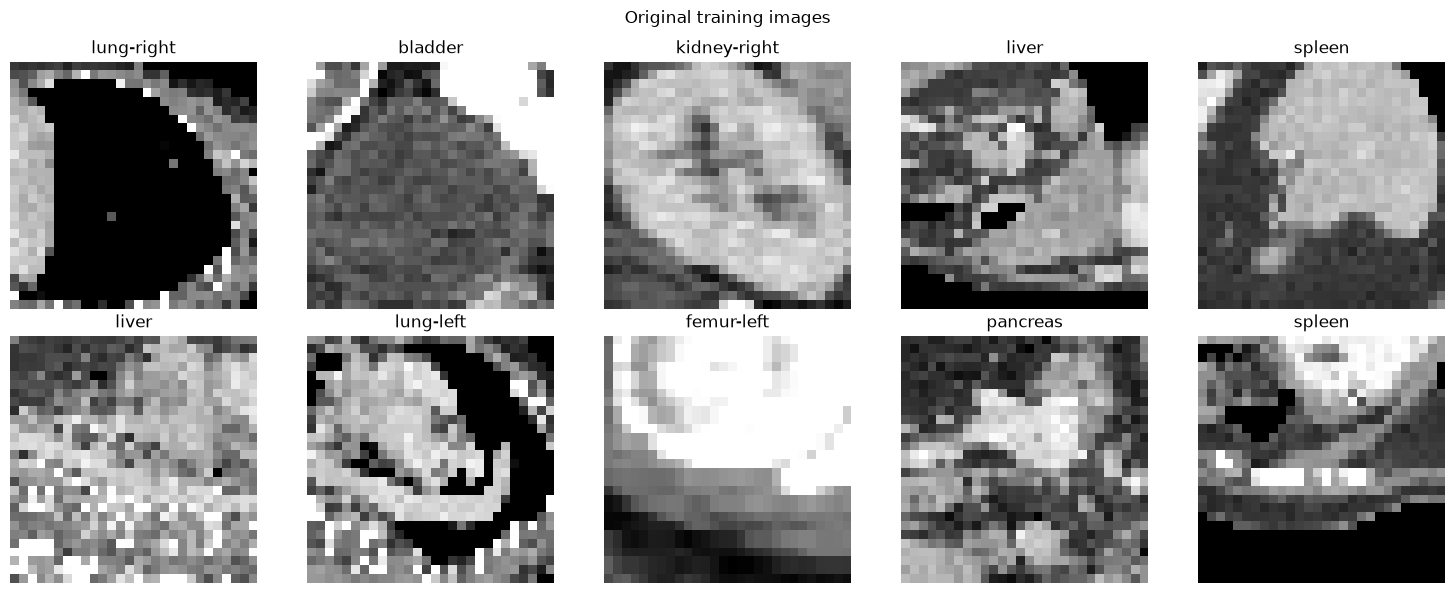

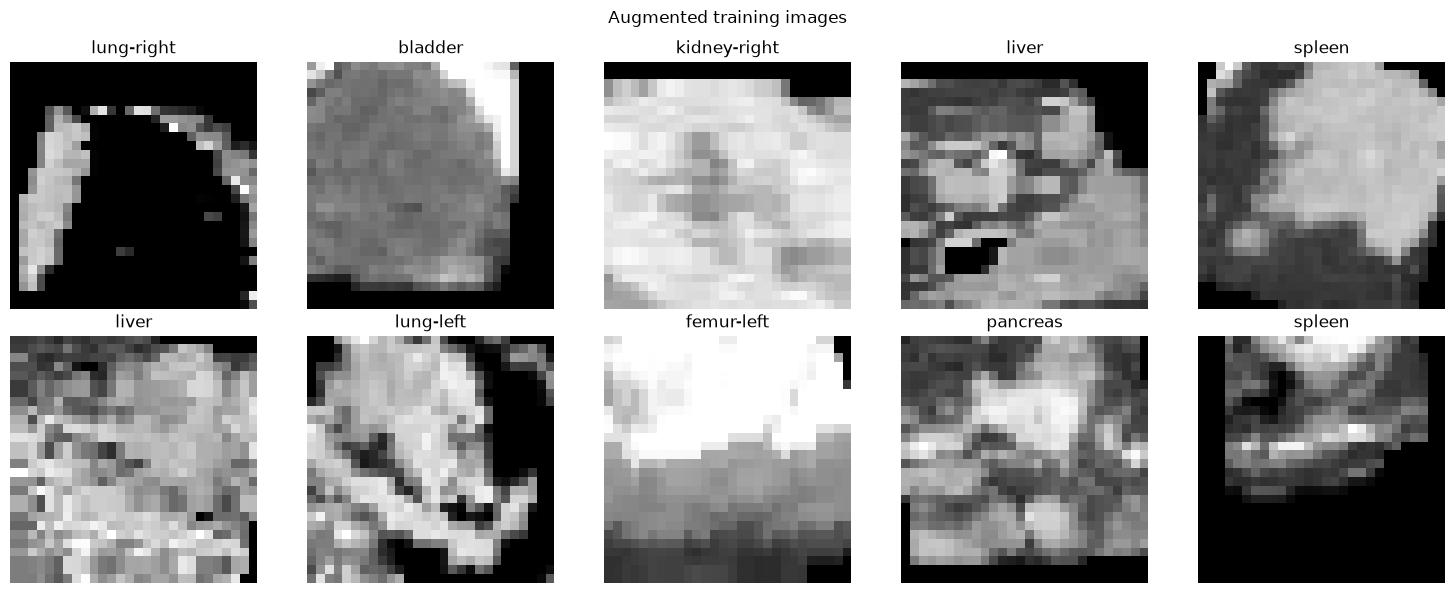

In [6]:
def plot_images(dataset, title, start_index=0):
    # Plot 10 images starting from start_index
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    fig.suptitle(title)

    for i, ax in enumerate(axes.flat):
        img, label = dataset[start_index + i]

        # Undo the normalization for display
        img = img.squeeze().cpu().numpy() * STD + MEAN
        img = np.clip(img, 0, 1)

        ax.imshow(img, cmap='gray')
        ax.set_title(CLASS_NAMES[str(label.item())])
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Plot the same training images without and with augmentation
plot_images(dataset_train, "Original training images")
plot_images(dataset_train_aug, "Augmented training images")

## Question
What is an example of when a data augmentation technique may not be helpful or even harmful to the performance of a model?

## Answer
The data augmentation that can be harmful for the model's performance include techniques that create false representation of human anatomy, change pixel values that are dignostically important or remove some key features. They may include:
- random vertical flips 
- horozontal flips or some extreme rotations (for asymmetrical organs)
- techniques that modify brightness or contrast,
- some harsh intensity transformation that alters the pixel intensity (especially in X-ray based images)
- extreme smoothing or noise introduction (this can make the key features invisible)


In [7]:
from cm2003.models import vgg


model = vgg.VGG13(num_classes=11, in_channels=1, use_dropout_conv = True)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model.to(device)

# Set number of epochs
num_epochs = 10


# Train the model
model, results_aug = train(model, loader_train_aug, loader_val, criterion, optimizer, device, num_epochs)

# Check accuracy on the test set
test_loss, test_accuracy = check_accuracy(model, loader_test, criterion, device)
train_loss, train_accuracy = check_accuracy(model, loader_train, criterion, device)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")

Epoch 1/10:
Train Loss: 1.9716
Val Loss: 1.5809, Val Accuracy: 0.4086
Epoch 2/10:
Train Loss: 1.4778
Val Loss: 1.1412, Val Accuracy: 0.5318
Epoch 3/10:
Train Loss: 1.2210
Val Loss: 1.1031, Val Accuracy: 0.5812
Epoch 4/10:
Train Loss: 1.0665
Val Loss: 0.6717, Val Accuracy: 0.7386
Epoch 5/10:
Train Loss: 0.9753
Val Loss: 0.7870, Val Accuracy: 0.6905
Epoch 6/10:
Train Loss: 0.8882
Val Loss: 0.6201, Val Accuracy: 0.7790
Epoch 7/10:
Train Loss: 0.8095
Val Loss: 0.7561, Val Accuracy: 0.7137
Epoch 8/10:
Train Loss: 0.7612
Val Loss: 0.4597, Val Accuracy: 0.8303
Epoch 9/10:
Train Loss: 0.7424
Val Loss: 0.5352, Val Accuracy: 0.8002
Epoch 10/10:
Train Loss: 0.7030
Val Loss: 0.5306, Val Accuracy: 0.7945
Test Loss: 0.8451, Test Accuracy: 0.6840
Train Loss: 0.5761, Train Accuracy: 0.7622


## Question
What differences do you observe in the training and validation loss curves when using data augmentation? Plot the training and validation loss curves for both cases (cell below).

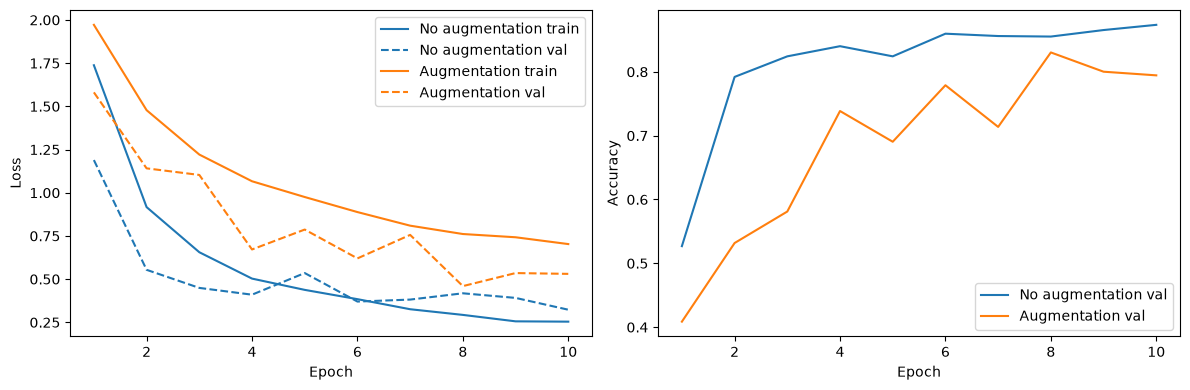

In [8]:
plot_results([results_baseline, results_aug], labels=['No augmentation', 'Augmentation'])

# Optimizers

Let's compare the performance of SGD and Adam optimizer. We will use the same model and the same dataset as above. Train the model with `torch.optim.SGD` (with momentum, e.g. `momentum=0.9`) and with `torch.optim.Adam`. Note that the two usually need different learning rates (e.g. around 0.01 to 0.1 for SGD and 0.001 for Adam). Compare the training and validation loss curves for both optimizers.

## Question
What are the advantages and disadvantages of using SGD and Adam optimizer?

In [9]:
# TODO Training with SGD and plot the training and validation loss curves
optimizer_sgd = torch.optim.SGD(model.parameters(),lr=0.01,momentum=0.9)
model, results_sgd = train(model, loader_train_aug, loader_val, criterion, optimizer_sgd, device, num_epochs)


Epoch 1/10:
Train Loss: 1.4976
Val Loss: 0.7173, Val Accuracy: 0.7614
Epoch 2/10:
Train Loss: 0.9667
Val Loss: 0.5632, Val Accuracy: 0.8144
Epoch 3/10:
Train Loss: 0.7949
Val Loss: 0.4495, Val Accuracy: 0.8336
Epoch 4/10:
Train Loss: 0.7358
Val Loss: 0.5185, Val Accuracy: 0.7936
Epoch 5/10:
Train Loss: 0.6991
Val Loss: 0.4446, Val Accuracy: 0.8348
Epoch 6/10:
Train Loss: 0.6708
Val Loss: 0.4204, Val Accuracy: 0.8507
Epoch 7/10:
Train Loss: 0.6509
Val Loss: 0.4198, Val Accuracy: 0.8385
Epoch 8/10:
Train Loss: 0.6314
Val Loss: 0.3680, Val Accuracy: 0.8679
Epoch 9/10:
Train Loss: 0.6454
Val Loss: 0.3777, Val Accuracy: 0.8361
Epoch 10/10:
Train Loss: 0.5997
Val Loss: 0.4075, Val Accuracy: 0.8405


In [10]:
# TODO Training with Adam and plot the training and validation loss curves
optimizer_adam = torch.optim.Adam(model.parameters(),lr=0.001)
model, results_adam = train(model, loader_train_aug, loader_val, criterion, optimizer_adam, device, num_epochs)
# plot_results([results_sgd, results_adam], labels=['SGD', 'Adam'])

Epoch 1/10:
Train Loss: 0.6337
Val Loss: 0.4376, Val Accuracy: 0.8295
Epoch 2/10:
Train Loss: 0.5943
Val Loss: 0.3995, Val Accuracy: 0.8414
Epoch 3/10:
Train Loss: 0.5780
Val Loss: 0.4278, Val Accuracy: 0.8385
Epoch 4/10:
Train Loss: 0.5833
Val Loss: 0.5777, Val Accuracy: 0.8067
Epoch 5/10:
Train Loss: 0.5614
Val Loss: 0.4467, Val Accuracy: 0.8442
Epoch 6/10:
Train Loss: 0.5548
Val Loss: 0.3637, Val Accuracy: 0.8683
Epoch 7/10:
Train Loss: 0.5284
Val Loss: 0.3792, Val Accuracy: 0.8675
Epoch 8/10:
Train Loss: 0.5109
Val Loss: 0.4618, Val Accuracy: 0.8259
Epoch 9/10:
Train Loss: 0.5181
Val Loss: 0.4079, Val Accuracy: 0.8471
Epoch 10/10:
Train Loss: 0.4973
Val Loss: 0.3590, Val Accuracy: 0.8728


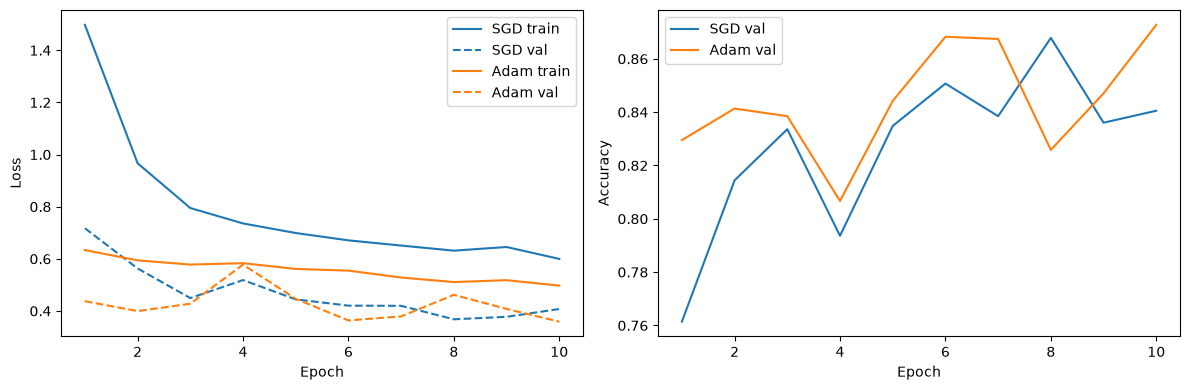

In [11]:
plot_results([results_sgd, results_adam], labels=['SGD', 'Adam'])

## Transfer learning

Transfer learning is a technique where a model trained on one task is reused as the starting point for training a model on a second, related task. This is useful when the second task has less data available than the first task.

### Using a pre-trained model

We will use a model pre-trained on ImageNet and fine-tune it on the OrganSMNIST dataset.

Look at the [torchvision documentation](https://docs.pytorch.org/vision/stable/models.html) to find out how to load a pre-trained model. Models are created with a `weights` argument, for example `models.resnet18(weights=None)` (random initialization) or `models.resnet18(weights=models.ResNet18_Weights.DEFAULT)` (pre-trained on ImageNet). The old `pretrained=True` argument has been removed.

1. Train the model from scratch (no pre-trained weights): replace the last layer with a new layer that has the number of classes in the OrganSMNIST dataset.

2. Load a pre-trained model, freeze all the layers of the model except the last one and replace the last layer with a new layer that has the number of classes in the OrganSMNIST dataset.

3. Load a pre-trained model, replace the last layer with a new layer that has the number of classes in the OrganSMNIST dataset and train the model on the OrganSMNIST dataset.

NOTE: We have changed the transform to make the images compatible with the pre-trained models:
- The single-channel image is converted to a 3-channel image by repeating it 3 times, because the pre-trained models expect RGB images.
- The images are normalized with the mean and standard deviation of ImageNet, which the pre-trained models were trained with.
- The images are upsampled from 28x28 to 64x64. The ImageNet models were trained on 224x224 images and downsample their input 32 times, so a 28x28 image would be reduced to a single pixel early in the network (and some models, such as VGG, would not work at all). Larger images give better results but train more slowly.

### 1. Training with a model from Torchvision from scratch

In [12]:
class RepeatChannelTransform:
    def __call__(self, img):
        # Repeat the single channel image to create a 3-channel image
        return img.repeat(3, 1, 1)

IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
IMG_SIZE = 64

# Transform with channel repetition, resizing and ImageNet normalization
transform_rgb = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Resize(IMG_SIZE),
    RepeatChannelTransform(),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Load medMNIST dataset
dataset_train_rgb = OrganSMNIST(root='cm2003/datasets', split='train', transform=transform_rgb, download=True)
loader_train_rgb = DataLoader(dataset_train_rgb, batch_size=64, shuffle=True)

dataset_val_rgb = OrganSMNIST(root='cm2003/datasets', split='val', transform=transform_rgb, download=True)
loader_val_rgb = DataLoader(dataset_val_rgb, batch_size=64, shuffle=False)

dataset_test_rgb = OrganSMNIST(root='cm2003/datasets', split='test', transform=transform_rgb, download=True)
loader_test_rgb = DataLoader(dataset_test_rgb, batch_size=64, shuffle=False)

In [13]:
# New image shape with duplicated channels
print(dataset_train_rgb[0][0].shape)

torch.Size([3, 64, 64])


In [14]:
from torchvision import models

model = None # TODO: Load a model from torchvision.models without pre-trained weights (weights=None), e.g. models.resnet18
model = models.resnet18(weights=None)
print(model)

# Replace the last layer with a new layer that has the number of classes in the OrganSMNIST dataset e.g.
model.fc = nn.Linear(model.fc.in_features, 11)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [15]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model.to(device)

# Set number of epochs
num_epochs = 10


# Train the model
model, results_scratch = train(model, loader_train_rgb, loader_val_rgb, criterion, optimizer, device, num_epochs)

# Check accuracy on the test set
test_loss, test_accuracy = check_accuracy(model, loader_test_rgb, criterion, device)
train_loss, train_accuracy = check_accuracy(model, loader_train_rgb, criterion, device)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")

Epoch 1/10:
Train Loss: 0.6992
Val Loss: 0.4262, Val Accuracy: 0.8409
Epoch 2/10:
Train Loss: 0.3671
Val Loss: 0.3999, Val Accuracy: 0.8524
Epoch 3/10:
Train Loss: 0.2546
Val Loss: 0.5115, Val Accuracy: 0.8426
Epoch 4/10:
Train Loss: 0.1807
Val Loss: 0.3728, Val Accuracy: 0.8679
Epoch 5/10:
Train Loss: 0.1411
Val Loss: 0.3820, Val Accuracy: 0.8801
Epoch 6/10:
Train Loss: 0.1291
Val Loss: 0.5065, Val Accuracy: 0.8552
Epoch 7/10:
Train Loss: 0.1082
Val Loss: 0.4330, Val Accuracy: 0.8719
Epoch 8/10:
Train Loss: 0.0955
Val Loss: 0.3477, Val Accuracy: 0.8846
Epoch 9/10:
Train Loss: 0.0880
Val Loss: 0.3933, Val Accuracy: 0.8911
Epoch 10/10:
Train Loss: 0.0843
Val Loss: 0.3696, Val Accuracy: 0.8817
Test Loss: 1.0972, Test Accuracy: 0.7470
Train Loss: 0.0955, Train Accuracy: 0.9536


### 2. Training with a pre-trained model and frozen layers

In [17]:
model = None # TODO: Load a model from torchvision.models with pre-trained weights, e.g. weights=models.ResNet18_Weights.DEFAULT
model= models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
# Freeze all the layers of the model except the last one
for param in model.parameters():
    param.requires_grad = False


# Replace the last layer with a new layer that has the number of classes in the OrganSMNIST dataset e.g.
model.fc = nn.Linear(model.fc.in_features, 11)
# (a newly created layer has requires_grad=True, so only this layer will be trained)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#TODO Train the model (use the *_rgb loaders) and store the results in results_frozen
model, results_frozen= train(model,loader_train_rgb, loader_val_rgb, criterion, optimizer, device, num_epochs)

Epoch 1/10:
Train Loss: 1.4657
Val Loss: 0.9549, Val Accuracy: 0.6823
Epoch 2/10:
Train Loss: 1.0439
Val Loss: 0.8470, Val Accuracy: 0.7162
Epoch 3/10:
Train Loss: 0.9502
Val Loss: 0.8188, Val Accuracy: 0.7023
Epoch 4/10:
Train Loss: 0.9103
Val Loss: 0.7780, Val Accuracy: 0.7247
Epoch 5/10:
Train Loss: 0.8824
Val Loss: 0.7852, Val Accuracy: 0.7251
Epoch 6/10:
Train Loss: 0.8560
Val Loss: 0.8061, Val Accuracy: 0.7092
Epoch 7/10:
Train Loss: 0.8558
Val Loss: 0.8029, Val Accuracy: 0.7206
Epoch 8/10:
Train Loss: 0.8281
Val Loss: 0.7899, Val Accuracy: 0.7223
Epoch 9/10:
Train Loss: 0.8249
Val Loss: 0.7940, Val Accuracy: 0.7239
Epoch 10/10:
Train Loss: 0.8170
Val Loss: 0.8377, Val Accuracy: 0.7055


### 3. Training with a pre-trained model and unfrozen layers

In [18]:
model = None # TODO: Load a model from torchvision.models with pre-trained weights
model= models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Replace the last layer with a new layer that has the number of classes in the OrganSMNIST dataset e.g.
model.fc = nn.Linear(model.fc.in_features, 11)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
#TODO Train the model (use the *_rgb loaders) and store the results in results_finetuned.
# Hint: fine-tuning a pre-trained model usually works best with a smaller learning rate than training from scratch.
model, results_finetuned= train(model,loader_train_rgb, loader_val_rgb, criterion, optimizer, device, num_epochs)


Epoch 1/10:
Train Loss: 0.5200
Val Loss: 0.3041, Val Accuracy: 0.8850
Epoch 2/10:
Train Loss: 0.2654
Val Loss: 0.2426, Val Accuracy: 0.8993
Epoch 3/10:
Train Loss: 0.2003
Val Loss: 0.3081, Val Accuracy: 0.8772
Epoch 4/10:
Train Loss: 0.1484
Val Loss: 0.2707, Val Accuracy: 0.8956
Epoch 5/10:
Train Loss: 0.1370
Val Loss: 0.2081, Val Accuracy: 0.9058
Epoch 6/10:
Train Loss: 0.1132
Val Loss: 0.2622, Val Accuracy: 0.9062
Epoch 7/10:
Train Loss: 0.1159
Val Loss: 0.2628, Val Accuracy: 0.9095
Epoch 8/10:
Train Loss: 0.1059
Val Loss: 0.2960, Val Accuracy: 0.9066
Epoch 9/10:
Train Loss: 0.0943
Val Loss: 0.3099, Val Accuracy: 0.9078
Epoch 10/10:
Train Loss: 0.0905
Val Loss: 0.2378, Val Accuracy: 0.9099


## Question
Compare the three transfer learning experiments (and the VGG results from earlier in this notebook). Which approach works best on OrganSMNIST, and why? When would you prefer to freeze the pre-trained layers instead of fine-tuning the whole model?

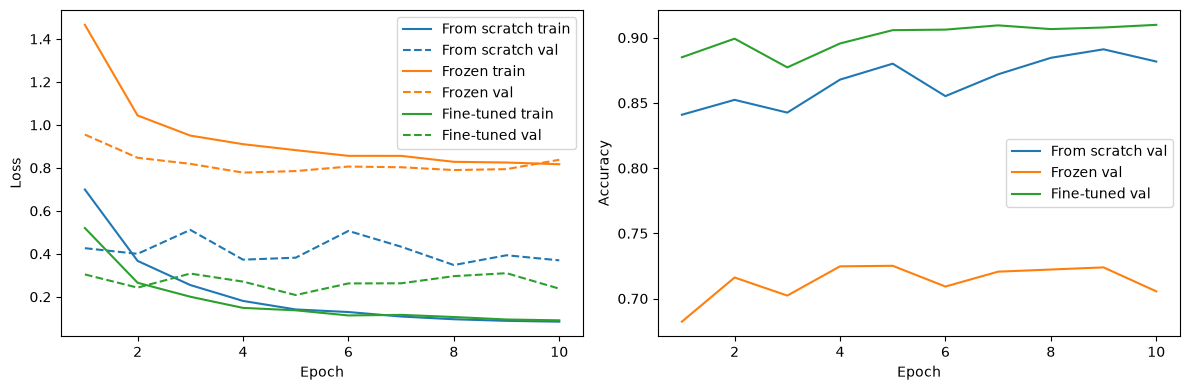

In [19]:
plot_results([results_scratch, results_frozen, results_finetuned], labels=['From scratch', 'Frozen', 'Fine-tuned'])